# 03 · Diagnóstico de calidad

Antes de modelar se mide qué tan confiables son las 724 series activas (producto × municipio): valores repetidos de un año a otro, saltos atípicos y longitud. Se ejecuta `src/ML_C/02_diagnostico.py`.

Reglas explícitas:
- **Repetido:** valor idéntico al del año anterior (años consecutivos, valor previo > 0).
- **Salto > 100 %:** variación anual mayor al 100 %.
- **Salto 3 DE:** variación estandarizada mayor a 3 desviaciones de la propia serie (series con ≥ 8 transiciones).
- **Confianza baja:** < 3 municipios, mediana < 12 años o > 50 % repetidos; **media:** > 30 % repetidos o > 15 % saltos.

In [1]:
import os, sys
from pathlib import Path
from importlib import import_module

ROOT = Path.cwd().resolve()
while not (ROOT / "config/ML_C/parametros.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src/ML_C"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import CFG, RAW, CLEAN, RES
from graficos import estilo, COLORES
estilo(); pd.set_option("display.max_columns", 30, "display.width", 160)

In [2]:
import_module("02_diagnostico").main()

series activas 724 | transiciones 12501 | repetidas 2613 (20.9 %) | saltos>100% 949 (7.6 %) | saltos 3sd 327
{'alta': 19, 'baja': 18, 'media': 7}
         producto       estado  n_municipios  anios_mediana  pct_repetidos  pct_saltos_100 confianza
        Guanábana    detallado            23           23.0           39.5             6.7     media
            Mango    detallado            18           17.0           37.6             6.2     media
           Borojó    detallado             1           24.0           34.8             4.3      baja
          Guayaba    detallado            30           23.5           33.3             6.8     media
              Vid    detallado            16           24.0           27.8             7.8      alta
         Aguacate    detallado            39           24.0           24.2             9.7      alta
           Sábila    detallado             9            9.0           24.1            12.1      baja
         Cítricos    detallado            37  

In [3]:
dq = pd.read_csv(RES / "diagnostico_calidad.csv")
pd.crosstab(dq.estado, dq.confianza, margins=True)

confianza,alta,baja,media,All
estado,,,,
detallado,15,3,4,22
simplificado,4,15,3,22
All,19,18,7,44


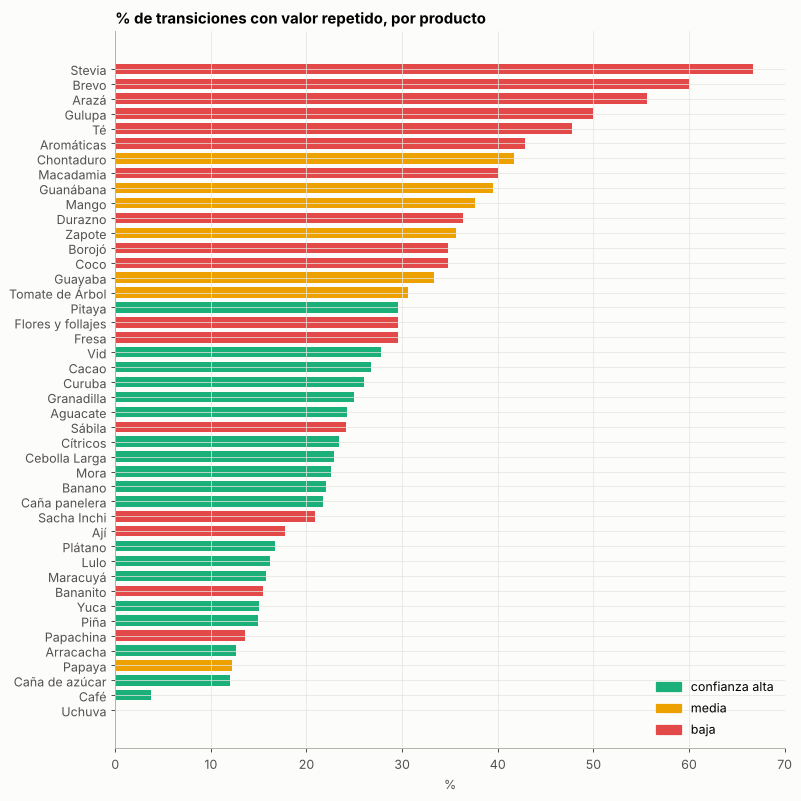

In [4]:
x = dq.sort_values("pct_repetidos")
fig, ax = plt.subplots(figsize=(9, 9))
col = x.confianza.map({"alta": COLORES[2], "media": COLORES[3], "baja": COLORES[7]})
ax.barh(x.producto, x.pct_repetidos, color=col, height=0.7)
ax.set_title("% de transiciones con valor repetido, por producto"); ax.set_xlabel("%")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORES[i], label=l) for i, l in [(2, "confianza alta"), (3, "media"), (7, "baja")]], loc="lower right")
plt.tight_layout(); plt.show()

Productos detallados que entran con confianza baja o media:

In [5]:
dq[(dq.estado == "detallado") & (dq.confianza != "alta")][["producto", "n_municipios", "anios_mediana", "pct_repetidos", "pct_saltos_100", "confianza"]]

,producto,n_municipios,anios_mediana,pct_repetidos,pct_saltos_100,confianza
0,Guanábana,23,23.0,39.5,6.7,media
1,Mango,18,17.0,37.6,6.2,media
2,Borojó,1,24.0,34.8,4.3,baja
3,Guayaba,30,23.5,33.3,6.8,media
6,Sábila,9,9.0,24.1,12.1,baja
12,Ají,20,11.5,17.8,11.0,baja
19,Papaya,23,19.0,12.2,16.7,media


## Lectura (para el informe de calidad)

In [6]:
print(open(ROOT / "docs/ML_C/lectura_diagnostico.md", encoding="utf-8").read())

# Lectura del diagnóstico de calidad (Ceyni → Carlos)

Se evaluaron 724 series activas (producto × municipio) de 44 productos. De 12.501 transiciones anuales comparables, 2.613 (20,9 %) repiten exactamente el valor del año anterior, y 949 (7,6 %) cambian más de 100 % respecto al año previo; 327 se salen de 3 desviaciones estándar de su propia serie. Una parte relevante de la serie parece estimación por consenso y no medición anual, y los saltos coinciden con cambios de metodología o de cobertura, no solo con la producción real. Hay además 295 registros con 0 t en el dato original y 18 filas duplicadas exactas (brevo y té), eliminadas.

Por confianza (reglas en src/02_diagnostico.py): 19 productos altos, 7 medios y 18 bajos. Entre los 22 detallados hay 15 de confianza alta, 4 media y 3 baja (Borojó, Sábila y Ají); entre los 22 simplificados predominan los de confianza baja (15), por tener pocos municipios o pocos años.

Implicación para el pronóstico: con 24 puntos anuales por serie, de